# ChestScan AI — CNN pour classer des radiographies (NORMAL vs PNEUMONIA)

**Étapes :** charger les données → explorer → vérifier les images → préparer (resize, RGB, labels, split, normalisation) → visualiser → déséquilibre → construire le CNN.

**Dataset :** Kaggle *Chest X-Ray Images (Pneumonia)* — `paultimothymooney/chest-xray-pneumonia`

## 1. Imports

In [ ]:
import os
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

## 2. Chargement et prétraitement du dataset

### 2.1 Charger le dataset

In [ ]:
DATA_DIR = Path(
    r"C:\Users\USER\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray"
)
print("Dossier trouvé :", DATA_DIR.exists())

Dossier trouvé : True


### 2.2 Explorer la structure des dossiers et identifier les classes

In [ ]:
for split in DATA_DIR.iterdir():
    if split.is_dir():                     
        for classe in split.iterdir():
            if classe.is_dir():
                print(split.name, "->", classe.name)

chest_xray -> test
chest_xray -> train
chest_xray -> val
test -> NORMAL
test -> PNEUMONIA
train -> NORMAL
train -> PNEUMONIA
val -> NORMAL
val -> PNEUMONIA
__MACOSX -> chest_xray


### 2.3 Nombre d'images par classe et répartition NORMAL / PNEUMONIA

In [ ]:
SPLITS = ["train", "val", "test"]
CLASSES = ["NORMAL", "PNEUMONIA"]
EXTENSIONS = {".jpg", ".jpeg", ".png"}

def compter_images(root, splits, classes):
    stats = {}
    for split in splits:
        stats[split] = {}
        for classe in classes:
            dossier = root / split / classe
            if dossier.is_dir():
                stats[split][classe] = sum(
                    1 for f in dossier.iterdir()
                    if f.is_file() and f.suffix.lower() in EXTENSIONS
                )
            else:
                print(f"Dossier introuvable : {dossier}")
                stats[split][classe] = 0
    return stats

df_stats = pd.DataFrame(compter_images(DATA_DIR, SPLITS, CLASSES)).T
df_stats["Total"] = df_stats[CLASSES].sum(axis=1)
df_stats["% PNEUMONIA"] = (df_stats["PNEUMONIA"] / df_stats["Total"] * 100).round(1)
print(df_stats)

       NORMAL  PNEUMONIA  Total  % PNEUMONIA
train    1341       3875   5216         74.3
val         8          8     16         50.0
test      234        390    624         62.5


### 2.4 Problèmes liés aux images (fichiers corrompus, modes, tailles)

In [ ]:
def rapport(dossier):
    stats = {"total": 0, "ok": 0, "corrompus": [], "modes": Counter(), "tailles": Counter()}
    for f in dossier.rglob("*"):
        if not f.is_file() or f.suffix.lower() not in EXTENSIONS:
            continue
        stats["total"] += 1
        try:
            with Image.open(f) as img:
                img.load()                           #force la lecture complète
                stats["modes"][img.mode] += 1        #L = gris, RGB = couleur
                stats["tailles"][img.size] += 1
                stats["ok"] += 1
        except Exception as e:
            stats["corrompus"].append((f, f"{type(e).__name__}: {e}"))
    return stats

for split in SPLITS:
    r = rapport(DATA_DIR / split)
    print(f"--- {split} ---")
    print("Total     :", r["total"])
    print("OK        :", r["ok"])
    print("Corrompus :", len(r["corrompus"]))
    print("Modes     :", dict(r["modes"]))
    print("Nb tailles différentes :", len(r["tailles"]))
    for f, err in r["corrompus"]:
        print("  Fichier à supprimer :", f, err)

--- train ---
Total     : 5216
OK        : 5216
Corrompus : 0
Modes     : {'L': 4933, 'RGB': 283}
Nb tailles différentes : 4366
--- val ---
Total     : 16
OK        : 16
Corrompus : 0
Modes     : {'L': 16}
Nb tailles différentes : 16
--- test ---
Total     : 624
OK        : 624
Corrompus : 0
Modes     : {'L': 624}
Nb tailles différentes : 598


### 2.5 Charger les images : resize 180×180, RGB, labels (noms des dossiers) et split train / validation / test

- `image_size=(180, 180)` : redimensionne toutes les images.
- `color_mode="rgb"` : convertit les images en 3 canaux (même celles en niveaux de gris).
- Les labels viennent des noms de dossiers (ordre alphabétique) : NORMAL = 0, PNEUMONIA = 1.
- Le dossier `val/` fourni contient seulement 16 images : trop peu pour valider. On prend donc **20 % de `train/`** comme validation.
- Le dossier `test/` n'est **jamais** utilisé pour l'entraînement : il reste indépendant.

In [ ]:
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

# 80 % de train/ pour l'entraînement
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, color_mode="rgb",
    batch_size=BATCH_SIZE, label_mode="binary",
)

# 20 % de train/ pour la validation 
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, color_mode="rgb",
    batch_size=BATCH_SIZE, label_mode="binary",
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    image_size=IMG_SIZE, color_mode="rgb",
    batch_size=BATCH_SIZE, label_mode="binary",
    shuffle=False,
)

class_names = train_ds.class_names
print("Classes :", class_names)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
Classes : ['NORMAL', 'PNEUMONIA']


### 2.6 Vérifier le format attendu par le CNN (3 canaux)

In [ ]:
for images, labels in train_ds.take(1):
    print("Forme des images :", images.shape)      # (batch, 180, 180, 3)
    print("Nombre de canaux :", images.shape[-1])  
    print("Type             :", images.dtype)
    print("Plage de pixels  :", images.numpy().min(), "->", images.numpy().max())

Forme des images : (32, 180, 180, 3)
Nombre de canaux : 3
Type             : <dtype: 'float32'>
Plage de pixels  : 0.0 -> 255.0


### 2.7 Associer les labels aux images (noms des dossiers)

In [ ]:
for i, nom in enumerate(class_names):
    print(f"{nom:10s} -> label {i}")

NORMAL     -> label 0
PNEUMONIA  -> label 1


### 2.8 Vérifier le split train / validation / test

In [ ]:
def compter(ds):
    return sum(len(labels) for _, labels in ds)

print("Train :", compter(train_ds))
print("Val   :", compter(val_ds))
print("Test  :", compter(test_ds))

Train : 4173
Val   : 1043
Test  : 624


### 2.10 Visualiser des images de chaque classe

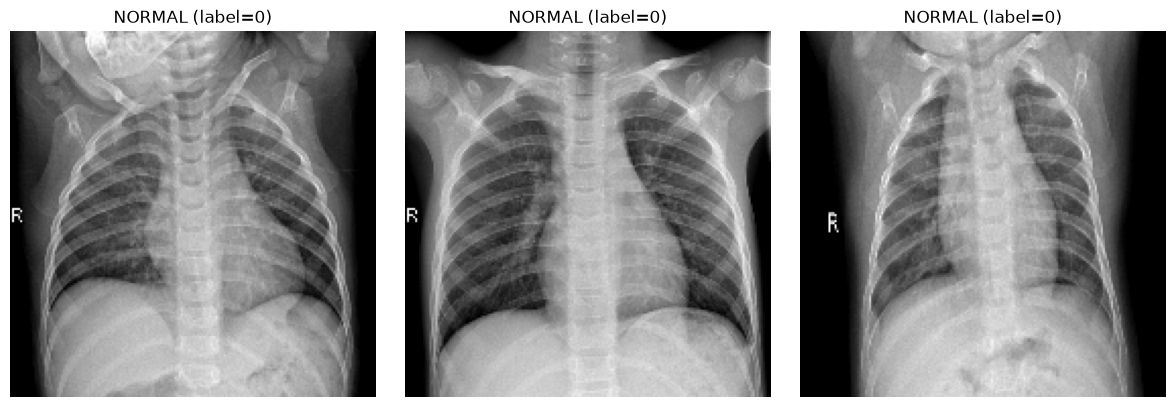

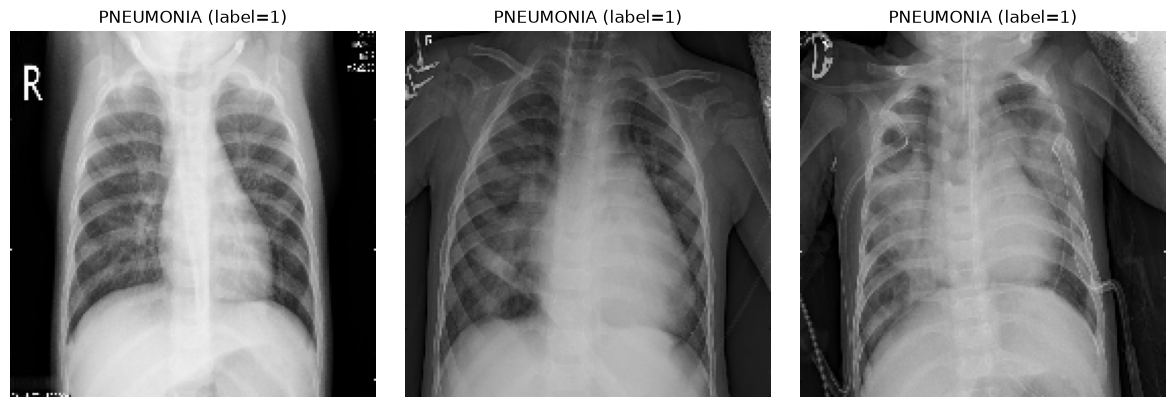

In [ ]:
def afficher_echantillons(ds, class_names, n=3):
    for images, labels in ds.take(1):
        images = images.numpy().astype("uint8")
        labels = labels.numpy().flatten()

        for classe_idx, classe_nom in enumerate(class_names):
            idxs = np.where(labels == classe_idx)[0][:n]
            if len(idxs) == 0:
                print(f"Aucune image {classe_nom} dans ce lot")
                continue

            fig, axes = plt.subplots(1, len(idxs), figsize=(4 * len(idxs), 4))
            axes = np.atleast_1d(axes)
            for ax, idx in zip(axes, idxs):
                ax.imshow(images[idx])
                ax.set_title(f"{classe_nom} (label={labels[idx]:.0f})")
                ax.axis("off")
            plt.tight_layout()
            plt.show()

afficher_echantillons(train_ds, class_names, n=3)

### 2.11 Distribution des classes

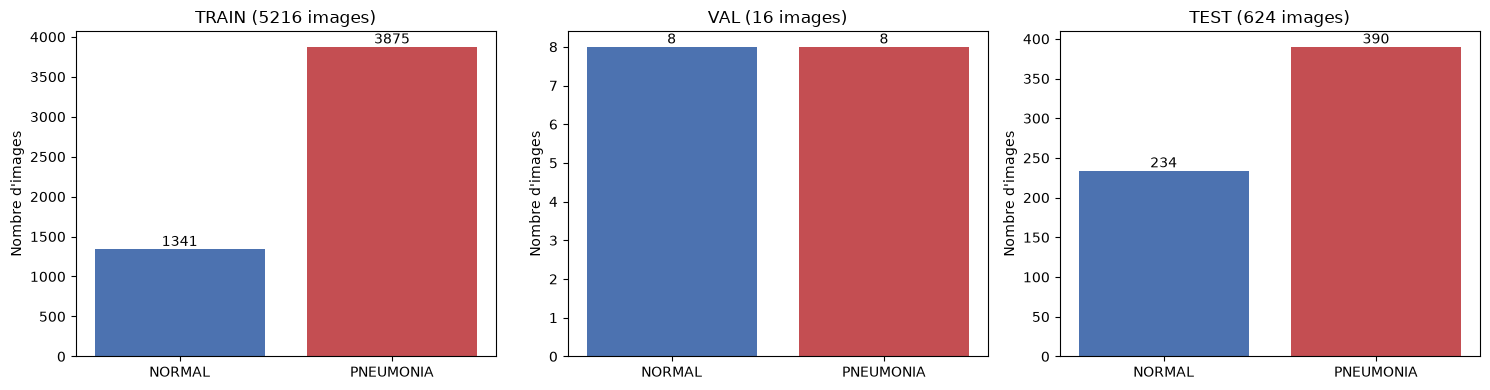

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, split in zip(axes, SPLITS):
    valeurs = [df_stats.loc[split, c] for c in CLASSES]
    bars = ax.bar(CLASSES, valeurs, color=["#4C72B0", "#C44E52"])
    ax.set_title(f"{split.upper()} ({sum(valeurs)} images)")
    ax.set_ylabel("Nombre d'images")
    for bar, v in zip(bars, valeurs):
        ax.text(bar.get_x() + bar.get_width() / 2, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

### 2.12 Déséquilibre des classes et stratégie

Il y a beaucoup plus d'images PNEUMONIA que NORMAL. Sans correction, le modèle peut prédire « PNEUMONIA » presque tout le temps.

**Stratégie :** `class_weight`. La classe rare (NORMAL) reçoit un poids plus grand pendant l'entraînement.

In [ ]:
n_normal = df_stats.loc["train", "NORMAL"]
n_pneumo = df_stats.loc["train", "PNEUMONIA"]
total = n_normal + n_pneumo

# Poids = total / (2 * nombre d'images de la classe)
# Clés : 0 = NORMAL, 1 = PNEUMONIA (même ordre que class_names)
class_weight = {
    0: total / (2 * n_normal),
    1: total / (2 * n_pneumo),
}
print("class_weight :", class_weight)

class_weight : {0: np.float64(1.9448173005219984), 1: np.float64(0.6730322580645162)}


## 3. Conception du modèle CNN

Un CNN (réseau de neurones convolutif) apprend automatiquement des motifs visuels (bords, formes, textures) :

- `Conv2D` : détecte des motifs dans l'image.
- `MaxPooling2D` : réduit la taille de l'image en gardant l'essentiel.
- `Flatten` : met les résultats à plat (un seul vecteur).
- `Dense` : prend la décision finale.
- `Dropout` : éteint des neurones au hasard pendant l'entraînement pour limiter le surapprentissage.
- Sortie `sigmoid` : donne une probabilité entre 0 et 1 (proche de 1 = PNEUMONIA).

### 3.1 Hyperparamètres

In [ ]:
EPOCHS = 20          # nombre de passages sur les données d'entraînement
LEARNING_RATE = 1e-3 # vitesse d'apprentissage de l'optimiseur Adam

### 3.2 Augmentation des images

Ces transformations aléatoires créent des variantes légères des images, seulement pendant l'entraînement.
Pas de flip horizontal : sur une radio, le côté du cœur est une information médicale.

In [ ]:
augmentation = keras.Sequential([
    layers.RandomRotation(0.05),   # petite rotation
    layers.RandomZoom(0.1),        # petit zoom
    layers.RandomContrast(0.1),    # petite variation de contraste
], name="augmentation")

### 3.3 Architecture, compilation et résumé

In [ ]:
model = models.Sequential([
    layers.Input(shape=(180, 180, 3)),        # images 180x180, 3 canaux

    augmentation,                             # actif seulement à l'entraînement
    layers.Rescaling(1./255),                 # normalisation [0, 1] (une seule fois)

    # 4 blocs : Conv2D (extrait des motifs) + MaxPooling2D (réduit la taille)
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Flatten(),                         # met les caractéristiques à plat
    layers.Dense(128, activation="relu"),     # couche de classification
    layers.Dropout(0.5),                      # limite le surapprentissage
    layers.Dense(1, activation="sigmoid"),    # sortie binaire (probabilité)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",               # perte adaptée à 2 classes
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 22, 22, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 11, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 15488)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,982,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,223,553 (8.48 MB)

 Trainable params: 2,223,553 (8.48 MB)

 Non-trainable params: 0 (0.00 B)

### 3.4 Entraînement (vérifier que le modèle apprend)

`class_weight` compense le déséquilibre. `EarlyStopping` arrête l'entraînement quand la validation ne s'améliore plus.

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=[early_stop],
)

Epoch 1/20


C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


131/131 ━━━━━━━━━━━━━━━━━━━━ 110s 796ms/step - accuracy: 0.6650 - auc: 0.8210 - loss: 0.5193 - val_accuracy: 0.9377 - val_auc: 0.9773 - val_loss: 0.1714
Epoch 2/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 130s 993ms/step - accuracy: 0.8962 - auc: 0.9585 - loss: 0.2637 - val_accuracy: 0.9041 - val_auc: 0.9863 - val_loss: 0.2272
Epoch 3/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 114s 779ms/step - accuracy: 0.9109 - auc: 0.9679 - loss: 0.2322 - val_accuracy: 0.9482 - val_auc: 0.9848 - val_loss: 0.1587
Epoch 4/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 99s 752ms/step - accuracy: 0.9274 - auc: 0.9789 - loss: 0.1841 - val_accuracy: 0.9406 - val_auc: 0.9910 - val_loss: 0.1577
Epoch 5/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 95s 725ms/step - accuracy: 0.9274 - auc: 0.9790 - loss: 0.1820 - val_accuracy: 0.9607 - val_auc: 0.9915 - val_loss: 0.1100
Epoch 6/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 102s 776ms/step - accuracy: 0.9408 - auc: 0.9830 - loss: 0.1617 - val_accuracy: 0.9645 - val_auc: 0.9910 - val_loss: 0.1150
Epoch 7/20
131/131 ━━━━━━━━━━